In [1]:
#Imports first

import numpy as np
import pandas as pd
import keras
from keras import layers
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

/Users/purnagamage/Documents/GitHub/Stock_Price_DL_2/.venv/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


Here is where you can change the configuration of the model to vary hyperparameters like learning rate, window, and horizon.

In [7]:
# ==========================================
# 1. STUDENT CONFIGURATION BLOCK
# ==========================================
# Change parameters here as necessary.
CONFIG = {
    "WINDOW": 40,                   # Lookback window (days of stock data) - do not set this too high. Range is 10-50 days.
    "HORIZON": 1,                   # Forecast horizon (days ahead) - do not set this too high. Range is 1-5 days.
    "EPOCHS": 30,                   # Number of training epochs. Keep an eye out for overfitting. Range is 10-50 epochs.
    "BATCH_SIZE": 32,               # Mini-batch size
    "LEARNING_RATE": 0.0003,        # Optimizer learning rate. Can vary from 0.0001 to 0.01 depending on model performance.
    "SEED": 42,                     # Random seed for reproducibility.
    "HIDDEN_UNITS": 32,             # Width of the recurrent layer. Can vary between 32, 64, and 128 units. More units = more model capacity, but also more risk of overfitting.
    "NUM_RECURRENT_LAYERS": 1,      # 1 or 2 stacked recurrent layers
    "DROPOUT_RATE": 0.2,            # Standard dropout between layers. Can range from 0.0 to 0.5. Helps prevent overfitting.
    "RECURRENT_DROPOUT": 0.1,       # Dropout on recurrent states. Can range from 0.0 to 0.5. Helps prevent overfitting.
    "L2_REGULARIZATION": 0.0001,      # Weight penalty. Can be 0.0001, 0.001, or 0.01, 0.1, or 0 depending on model performance.
    "EARLY_STOPPING_PATIENCE": 5,   # Number of epochs to wait for improvement before stopping

    # Paths to files
    #=============================
    # UPDATE WITH YOUR LOCAL PATHS
    #=============================
    "STOCKS_PATH": "all_stocks_wide.csv",
    "JOBS_PATH": "all_job_postings.csv",

    # Feature & Target column names. Remember to only set one target column for regression tasks.
    #=============================
    # UPDATE WITH YOUR COLUMN NAMES
    #=============================
    "FEATURES": ["MSFT", "AI", "NVDA", "GOOGL"],
    "TARGET": "Data Analysis"
}

# Set environment seed for reproducibility
keras.utils.set_random_seed(CONFIG["SEED"])

Here is where we load, align, and split the data so that we have train/val/test splits, as well as properly formatted data (samples, time steps, features). We also scale all data.

In [17]:
# ==========================================
# 2. DATA LOAD, ALIGNMENT, & SPLIT
# ==========================================
# UPDATE THE PATHS IN CONFIG ABOVE TO POINT TO YOUR LOCAL FILES
# Note: You may need to change column names to match your dataset.

from pathlib import Path
import pandas as pd

BASE_PATH = Path(
    "/Users/purnagamage/Documents/GitHub/DS-Corps-Assessents"
)

CONFIG = {
    "STOCKS_PATH": BASE_PATH / "df_stocks.csv",
    "JOBS_PATH": BASE_PATH / "df_jobs.csv",
}

df_stocks = pd.read_csv(
    CONFIG["STOCKS_PATH"],
    parse_dates=["Date"],
)

df_jobs = pd.read_csv(
    CONFIG["JOBS_PATH"],
    parse_dates=["Date"],
)

df_stocks = (
    df_stocks
    .sort_values("Date")
    .reset_index(drop=True)
)

df_jobs = (
    df_jobs
    .sort_values("Date")
    .reset_index(drop=True)
)

print(df_stocks.head())
print(df_jobs.head())
print(df_stocks.columns)
print(df_jobs.columns)







        Date        MSFT        C3AI       NVDA      GOOGL
0 2020-12-09  202.329514   92.489998  12.893788  88.111694
1 2020-12-10  201.106720  130.000000  12.935171  87.605675
2 2020-12-11  203.724228  119.580002  12.976055  87.960045
3 2020-12-12  204.023544  113.840001  13.074274  87.587680
4 2020-12-13  204.322861  108.100001  13.172494  87.215314
        Date     DA     SW    ALL
0 2020-12-09  81.56  89.53  94.44
1 2020-12-10  81.77  89.51  94.45
2 2020-12-11  82.00  89.63  94.56
3 2020-12-12  82.13  89.47  94.54
4 2020-12-13  82.52  89.69  94.73
Index(['Date', 'MSFT', 'C3AI', 'NVDA', 'GOOGL'], dtype='object')
Index(['Date', 'DA', 'SW', 'ALL'], dtype='object')


In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

# ==========================================
# 1. CONFIGURATION
# ==========================================

BASE_PATH = Path(
    "/Users/purnagamage/Documents/GitHub/DS-Corps-Assessents"
)

CONFIG = {
    "WINDOW": 40,
    "HORIZON": 1,
    "EPOCHS": 30,
    "BATCH_SIZE": 32,
    "LEARNING_RATE": 0.0003,
    "SEED": 42,
    "HIDDEN_UNITS": 32,
    "NUM_RECURRENT_LAYERS": 1,
    "DROPOUT_RATE": 0.2,
    "RECURRENT_DROPOUT": 0.1,
    "L2_REGULARIZATION": 0.0001,
    "EARLY_STOPPING_PATIENCE": 5,

    # Files exported from R
    "STOCKS_PATH": BASE_PATH / "df_stocks.csv",
    "JOBS_PATH": BASE_PATH / "df_jobs.csv",

    # Columns in the files exported from R
    "FEATURES": [
        "MSFT",
        "C3AI",
        "NVDA",
        "GOOGL",
    ],

    # Choose one: DA, SW, or ALL
    "TARGET": "DA",
}

# Set seed
keras.utils.set_random_seed(
    CONFIG["SEED"]
)

# Confirm that the correct configuration is active
print("CONFIG keys:")
print(CONFIG.keys())

print("\nWindow:", CONFIG["WINDOW"])
print("Stock file:", CONFIG["STOCKS_PATH"])
print("Jobs file:", CONFIG["JOBS_PATH"])

CONFIG keys:
dict_keys(['WINDOW', 'HORIZON', 'EPOCHS', 'BATCH_SIZE', 'LEARNING_RATE', 'SEED', 'HIDDEN_UNITS', 'NUM_RECURRENT_LAYERS', 'DROPOUT_RATE', 'RECURRENT_DROPOUT', 'L2_REGULARIZATION', 'EARLY_STOPPING_PATIENCE', 'STOCKS_PATH', 'JOBS_PATH', 'FEATURES', 'TARGET'])

Window: 40
Stock file: /Users/purnagamage/Documents/GitHub/DS-Corps-Assessents/df_stocks.csv
Jobs file: /Users/purnagamage/Documents/GitHub/DS-Corps-Assessents/df_jobs.csv


In [19]:

# Align datasets
df_merged = pd.merge(df_stocks, df_jobs, on='Date', how='inner').sort_values('Date').reset_index(drop=True)

# Chronological split
N = len(df_merged)
n_train = int(0.70 * N)
n_val   = int(0.15 * N)

train_raw = df_merged.iloc[:n_train]
val_raw   = df_merged.iloc[n_train - CONFIG["WINDOW"] : n_train + n_val]
test_raw  = df_merged.iloc[n_train + n_val - CONFIG["WINDOW"] :]


# ==========================================
# 3. ROBUST PREPROCESSING (STRICT SCALING)
# ==========================================
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Transform Features
X_train_scaled = scaler_X.fit_transform(train_raw[CONFIG["FEATURES"]].values)
X_val_scaled   = scaler_X.transform(val_raw[CONFIG["FEATURES"]].values)
X_test_scaled  = scaler_X.transform(test_raw[CONFIG["FEATURES"]].values)

# Transform Target
y_train_scaled = scaler_y.fit_transform(train_raw[[CONFIG["TARGET"]]].values)
y_val_scaled   = scaler_y.transform(val_raw[[CONFIG["TARGET"]]].values)
y_test_scaled  = scaler_y.transform(test_raw[[CONFIG["TARGET"]]].values)

# Window Generator
def make_multivariate_windows(features_arr, target_arr, window, horizon):
    X, y = [], []
    for i in range(len(features_arr) - window - horizon + 1):
        X.append(features_arr[i : i + window])
        y.append(target_arr[i + window + horizon - 1])
    return np.array(X), np.array(y)

X_train, y_train = make_multivariate_windows(X_train_scaled, y_train_scaled, CONFIG["WINDOW"], CONFIG["HORIZON"])
X_val, y_val     = make_multivariate_windows(X_val_scaled, y_val_scaled, CONFIG["WINDOW"], CONFIG["HORIZON"])
X_test, y_test   = make_multivariate_windows(X_test_scaled, y_test_scaled, CONFIG["WINDOW"], CONFIG["HORIZON"])

The code below constructs and compiles various models based on your selection. The idea here is to compare performance across different architectures (RNN, GRU, LSTM), and across different hyperparameters (set in the config above).

In [20]:
# ==========================================
# 4. DYNAMIC MODEL BUILDER
# ==========================================
def build_recurrent_model(model_type, window, num_features, config):
    """
    Constructs an RNN model supporting regularization, dropout,
    and variable stack depth.
    """
    model = keras.Sequential()

    # Define L2 Regularizer if active
    reg = keras.regularizers.l2(config["L2_REGULARIZATION"]) if config["L2_REGULARIZATION"] > 0 else None

    # 1. Recurrent Layers (Handling Stacked Layers)
    for i in range(config["NUM_RECURRENT_LAYERS"]):
        # If stacking recurrent layers, intermediate layers MUST return sequences
        return_seq = True if (i < config["NUM_RECURRENT_LAYERS"] - 1) else False

        # Configure the layer keyword arguments
        layer_kwargs = {
            "units": config["HIDDEN_UNITS"],
            "activation": "tanh",
            "return_sequences": return_seq,
            "dropout": config["DROPOUT_RATE"],
            "recurrent_dropout": config["RECURRENT_DROPOUT"],
            "kernel_regularizer": reg
        }

        # Only define input_shape on the very first layer
        if i == 0:
            layer_kwargs["input_shape"] = (window, num_features)

        if model_type.upper() == "SIMPLERNN":
            model.add(layers.SimpleRNN(**layer_kwargs))
        elif model_type.upper() == "LSTM":
            model.add(layers.LSTM(**layer_kwargs))
        elif model_type.upper() == "GRU":
            model.add(layers.GRU(**layer_kwargs))

    # 2. Dense Regularization Block
    model.add(layers.Dense(32, activation="relu"))
    if config["DROPOUT_RATE"] > 0:
        model.add(layers.Dropout(config["DROPOUT_RATE"]))

    # 3. Output layer (single continuous prediction)
    model.add(layers.Dense(1))

    optimizer = keras.optimizers.Adam(learning_rate=config["LEARNING_RATE"])
    model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])
    return model

Below is the actual model building, training, validation, and testing process, i.e. the entire deep learning process.

In [21]:
# ==========================================
# 5. MULTI-MODEL COMPARISON PIPELINE
# ==========================================
architectures = ["SimpleRNN", "LSTM", "GRU"]
results = {}
predictions = {}

for arch in architectures:
    print(f"\n--- Training {arch} Model ---")
    model = build_recurrent_model(
        model_type=arch,
        window=CONFIG["WINDOW"],
        num_features=len(CONFIG["FEATURES"]),
        config=CONFIG
    )

    # Define Early Stopping Callback
    early_stop = EarlyStopping(
        monitor='val_loss',             # Monitors validation MSE
        patience=CONFIG["EARLY_STOPPING_PATIENCE"],  # Stops after X epochs of no improvement
        restore_best_weights=True,     # Crucial: Rolls back model weights to the absolute best epoch
        verbose=1
    )

    # Train
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=CONFIG["EPOCHS"],
        batch_size=CONFIG["BATCH_SIZE"],
        callbacks=[early_stop],
        verbose=1
    )

    # Predict and inverse scale
    y_pred_scaled = model.predict(X_test, verbose=0)
    y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()
    y_true = scaler_y.inverse_transform(y_test).flatten()

    predictions[arch] = y_pred

    # Calculate performance metrics
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = 100 * np.mean(np.abs((y_true - y_pred) / y_true))

    results[arch] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE%": mape,
        "history": history.history
    }



--- Training SimpleRNN Model ---
Epoch 1/30


/Users/purnagamage/Documents/GitHub/Stock_Price_DL_2/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.9149 - mae: 0.7998 - val_loss: 0.0922 - val_mae: 0.2904
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6903 - mae: 0.6780 - val_loss: 0.1730 - val_mae: 0.4045
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5749 - mae: 0.6118 - val_loss: 0.1506 - val_mae: 0.3775
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5535 - mae: 0.5972 - val_loss: 0.0992 - val_mae: 0.3051
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5005 - mae: 0.5612 - val_loss: 0.1343 - val_mae: 0.3588
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4603 - mae: 0.5304 - val_loss: 0.0381 - val_mae: 0.1822
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4742 - mae: 0.5382 - val_loss: 0.0443 - val_mae: 0.2004
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4937 - mae: 0.5453 - val_loss: 0.0307 - val_mae: 0.1647
Epoch 9/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4346 - mae: 0.5193 - va

/Users/purnagamage/Documents/GitHub/Stock_Price_DL_2/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.8331 - mae: 0.7790 - val_loss: 0.1961 - val_mae: 0.4364
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5587 - mae: 0.5976 - val_loss: 0.0055 - val_mae: 0.0491
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3634 - mae: 0.4710 - val_loss: 0.0058 - val_mae: 0.0605
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2887 - mae: 0.4015 - val_loss: 0.0042 - val_mae: 0.0433
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2941 - mae: 0.3911 - val_loss: 0.0184 - val_mae: 0.1208
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2921 - mae: 0.3831 - val_loss: 0.0254 - val_mae: 0.1479
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2811 - mae: 0.3728 - val_loss: 0.0160 - val_mae: 0.1117
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2828 - mae: 0.3774 - val_loss: 0.0222 - val_mae: 0.1369
Epoch 9/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2441 - mae: 0.3487 - va

/Users/purnagamage/Documents/GitHub/Stock_Price_DL_2/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1.1086 - mae: 0.8814 - val_loss: 0.0640 - val_mae: 0.2091
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8581 - mae: 0.7794 - val_loss: 0.0147 - val_mae: 0.0947
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7025 - mae: 0.7014 - val_loss: 0.0353 - val_mae: 0.1669
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6121 - mae: 0.6531 - val_loss: 0.0244 - val_mae: 0.1375
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5592 - mae: 0.6221 - val_loss: 0.0428 - val_mae: 0.1802
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5269 - mae: 0.5978 - val_loss: 0.0458 - val_mae: 0.1850
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4614 - mae: 0.5580 - val_loss: 0.0262 - val_mae: 0.1363
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.


In [23]:
from pathlib import Path

import numpy as np
import pandas as pd

# ==========================================
# 6. CREATE PREDICTION DATA FOR DM TEST
# ==========================================

# Map Python target names to the labels used in R
target_label_map = {
    "DA": "DA Job Openings",
    "Data Analysis": "DA Job Openings",

    "SW": "SW Job Openings",
    "Software Development": "SW Job Openings",

    "ALL": "All Job Openings",
    "All Job Openings": "All Job Openings",
}

target_name = CONFIG["TARGET"]

job_type_label = target_label_map.get(
    target_name,
    target_name,
)

# ------------------------------------------------------------
# Get the dates corresponding exactly to y_test
# ------------------------------------------------------------

# The first WINDOW observations are used as predictors.
# HORIZON determines which future observation is the target.
first_prediction_position = (
    CONFIG["WINDOW"]
    + CONFIG["HORIZON"]
    - 1
)

test_dates = (
    test_raw["Date"]
    .iloc[first_prediction_position:]
    .reset_index(drop=True)
)

# Convert arrays to one-dimensional form
y_true_dm = np.asarray(
    y_true
).reshape(-1)

# Verify date and outcome alignment
if len(test_dates) != len(y_true_dm):
    raise ValueError(
        "Date and actual-value lengths do not match: "
        f"dates={len(test_dates)}, "
        f"actual={len(y_true_dm)}"
    )


def create_dm_prediction_data(
    dates,
    actual,
    predicted,
    job_type,
    model_name,
):
    """
    Create the long-format prediction data needed
    for a Diebold-Mariano comparison.
    """

    actual = np.asarray(
        actual
    ).reshape(-1)

    predicted = np.asarray(
        predicted
    ).reshape(-1)

    dates = pd.to_datetime(
        dates
    ).reset_index(drop=True)

    if not (
        len(dates)
        == len(actual)
        == len(predicted)
    ):
        raise ValueError(
            f"Length mismatch for {model_name}: "
            f"dates={len(dates)}, "
            f"actual={len(actual)}, "
            f"predicted={len(predicted)}"
        )

    prediction_data = pd.DataFrame(
        {
            "Date": dates,
            "Job_Type": job_type,
            "Actual": actual,
            "Predicted": predicted,
            "Model": model_name,
        }
    )

    required_numeric = prediction_data[
        ["Actual", "Predicted"]
    ].to_numpy()

    if not np.isfinite(required_numeric).all():
        raise ValueError(
            f"{model_name} prediction data contain "
            "NaN or infinite values."
        )

    return prediction_data

In [24]:
# ==========================================
# 7. MODEL-SPECIFIC PREDICTION DATA
# ==========================================

rnn_prediction_data = create_dm_prediction_data(
    dates=test_dates,
    actual=y_true_dm,
    predicted=predictions["SimpleRNN"],
    job_type=job_type_label,
    model_name="SimpleRNN",
)

lstm_prediction_data = create_dm_prediction_data(
    dates=test_dates,
    actual=y_true_dm,
    predicted=predictions["LSTM"],
    job_type=job_type_label,
    model_name="LSTM",
)

gru_prediction_data = create_dm_prediction_data(
    dates=test_dates,
    actual=y_true_dm,
    predicted=predictions["GRU"],
    job_type=job_type_label,
    model_name="GRU",
)

print("\nSimpleRNN predictions:")
print(rnn_prediction_data.head())

print("\nLSTM predictions:")
print(lstm_prediction_data.head())

print("\nGRU predictions:")
print(gru_prediction_data.head())


SimpleRNN predictions:
        Date         Job_Type  Actual  Predicted      Model
0 2025-03-30  DA Job Openings   63.22  64.310486  SimpleRNN
1 2025-03-31  DA Job Openings   63.33  64.811905  SimpleRNN
2 2025-04-01  DA Job Openings   63.55  64.278091  SimpleRNN
3 2025-04-02  DA Job Openings   63.68  64.558830  SimpleRNN
4 2025-04-03  DA Job Openings   63.74  64.245369  SimpleRNN

LSTM predictions:
        Date         Job_Type  Actual  Predicted Model
0 2025-03-30  DA Job Openings   63.22  69.276215  LSTM
1 2025-03-31  DA Job Openings   63.33  69.333496  LSTM
2 2025-04-01  DA Job Openings   63.55  69.382599  LSTM
3 2025-04-02  DA Job Openings   63.68  69.244400  LSTM
4 2025-04-03  DA Job Openings   63.74  69.209526  LSTM

GRU predictions:
        Date         Job_Type  Actual  Predicted Model
0 2025-03-30  DA Job Openings   63.22  77.911880   GRU
1 2025-03-31  DA Job Openings   63.33  78.740616   GRU
2 2025-04-01  DA Job Openings   63.55  79.155563   GRU
3 2025-04-02  DA Job Openings

In [25]:
dl_stock_prediction_data = pd.concat(
    [
        rnn_prediction_data,
        lstm_prediction_data,
        gru_prediction_data,
    ],
    ignore_index=True,
)

print(dl_stock_prediction_data.head())
print(dl_stock_prediction_data.groupby("Model").size())

        Date         Job_Type  Actual  Predicted      Model
0 2025-03-30  DA Job Openings   63.22  64.310486  SimpleRNN
1 2025-03-31  DA Job Openings   63.33  64.811905  SimpleRNN
2 2025-04-01  DA Job Openings   63.55  64.278091  SimpleRNN
3 2025-04-02  DA Job Openings   63.68  64.558830  SimpleRNN
4 2025-04-03  DA Job Openings   63.74  64.245369  SimpleRNN
Model
GRU          278
LSTM         278
SimpleRNN    278
dtype: int64


In [26]:
# Folder for saved results
OUTPUT_PATH = Path(
    "/Users/purnagamage/Documents/GitHub/DS-Corps-Assessents"
)

OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True,
)

# Safe target name for filenames
target_file_name = (
    str(CONFIG["TARGET"])
    .replace(" ", "_")
    .replace("/", "_")
)

# Save separate files
rnn_prediction_data.to_csv(
    OUTPUT_PATH
    / f"stock_SimpleRNN_{target_file_name}_predictions.csv",
    index=False,
)

lstm_prediction_data.to_csv(
    OUTPUT_PATH
    / f"stock_LSTM_{target_file_name}_predictions.csv",
    index=False,
)

gru_prediction_data.to_csv(
    OUTPUT_PATH
    / f"stock_GRU_{target_file_name}_predictions.csv",
    index=False,
)

# Save one combined file
combined_output_file = (
    OUTPUT_PATH
    / f"stock_DL_{target_file_name}_predictions.csv"
)

dl_stock_prediction_data.to_csv(
    combined_output_file,
    index=False,
)

print(
    "Combined predictions saved to:",
    combined_output_file,
)

Combined predictions saved to: /Users/purnagamage/Documents/GitHub/DS-Corps-Assessents/stock_DL_DA_predictions.csv


Performance Summary Table to compare results across models.

In [22]:
# ==========================================
# 6. PERFORMANCE SUMMARY TABLE
# ==========================================
df_metrics = pd.DataFrame(results).T.drop(columns=['history'])
print("\n=== FINAL TEST PERFORMANCE COMPARISON ===")
print(df_metrics.to_markdown())


=== FINAL TEST PERFORMANCE COMPARISON ===


ImportError: Missing optional dependency 'tabulate'.  Use pip or conda to install tabulate.

Performance visulaizations

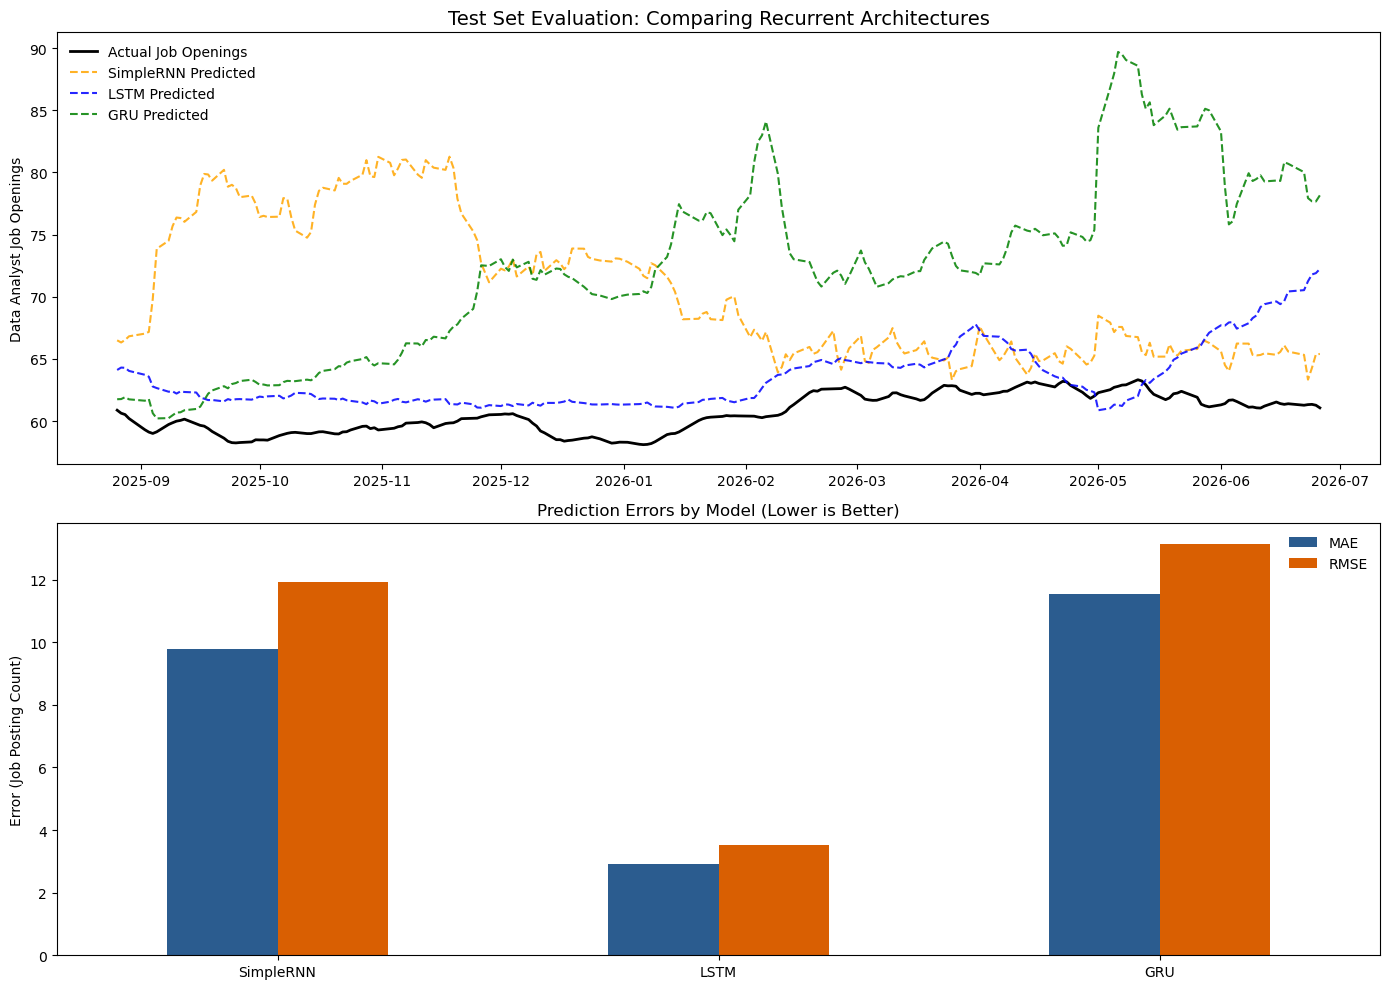

In [30]:
# ==========================================
# 7. COMPARATIVE VISUALIZATIONS
# ==========================================
test_dates = df_merged['Date'].iloc[-len(y_test):].values

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

# Top Plot: Actual vs Model Predictions
axes[0].plot(test_dates, y_true, color="black", label='Actual Job Openings', lw=2, zorder=1)
colors = {"SimpleRNN": "orange", "LSTM": "blue", "GRU": "green"}

for arch in architectures:
    axes[0].plot(test_dates, predictions[arch], color=colors[arch],
                 label=f'{arch} Predicted', linestyle='--', alpha=0.85, lw=1.5)

axes[0].set_title('Test Set Evaluation: Comparing Recurrent Architectures', fontsize=14)
axes[0].set_ylabel('Data Analyst Job Openings')
axes[0].legend(frameon=False)

# Bottom Plot: Metric Benchmarks (R2 and MAE)
ax_metrics = axes[1]
df_metrics[['MAE', 'RMSE']].plot(kind='bar', ax=ax_metrics, color=['#2b5c8f', '#d95f02'])
ax_metrics.set_title('Prediction Errors by Model (Lower is Better)', fontsize=12)
ax_metrics.set_xticklabels(df_metrics.index, rotation=0)
ax_metrics.set_ylabel('Error (Job Posting Count)')
ax_metrics.legend(frameon=False)

plt.tight_layout()
plt.show()

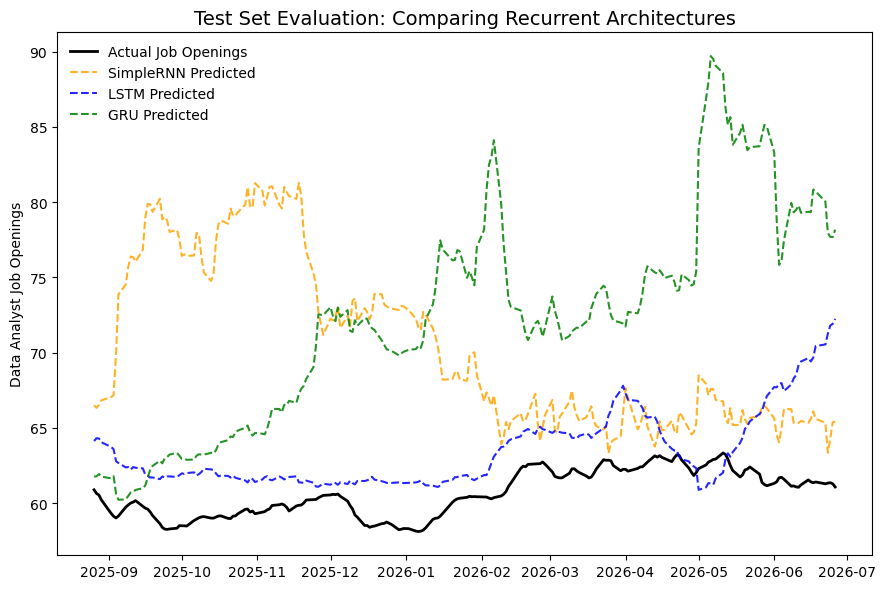

: 

In [ ]:
# ==========================================
# 7. COMPARATIVE VISUALIZATIONS
# ==========================================
test_dates = df_merged['Date'].iloc[-len(y_test):].values

fig, ax = plt.subplots(figsize=(9, 6))

# Actual vs Model Predictions
ax.plot(test_dates, y_true, color="black", label='Actual Job Openings', lw=2, zorder=1)
colors = {"SimpleRNN": "orange", "LSTM": "blue", "GRU": "green"}

for arch in architectures:
    ax.plot(test_dates, predictions[arch], color=colors[arch],
            label=f'{arch} Predicted', linestyle='--', alpha=0.85, lw=1.5)

ax.set_title('Test Set Evaluation: Comparing Recurrent Architectures', fontsize=14)
ax.set_ylabel('Data Analyst Job Openings')
ax.legend(frameon=False)

plt.tight_layout()
plt.show()